# Credit Risk Classification with Logistic Regression

## Objective
Build a baseline binary classifier to predict loan default (`loan_status = 1`) versus non-default (`loan_status = 0`). This exploratory project covers data inspection, cleaning, categorical encoding, logistic-regression modeling, classification metrics, ROC analysis, and threshold selection.

## Workflow
1. Inspect the dataset and explore a relationship in the data.
2. Review an extreme employment-length value and handle missing data.
3. Encode categorical predictors and define the target.
4. Fit a logistic-regression baseline and evaluate it.
5. Examine the confusion matrix, ROC curve, and threshold trade-offs.
6. Explore the threshold that maximizes F1.

> **Scope:** This is a learning/portfolio baseline, not a production-ready lending model. Important validation limitations and next steps are documented at the end.

In [1]:
# Core data handling and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model development and evaluation utilities
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, auc, classification_report,
)

# Load the dataset. This relative path assumes the notebook is one folder below `data/`.
# Update the path if your project structure differs.
cr_loan = pd.read_csv(r"..\data\raw\credit_risk_dataset.csv")

# Inspect dimensions: (number of rows, number of columns)
cr_loan.shape

(32581, 12)

## 1. Initial data inspection

Check the dataset dimensions and preview a few records. For a fuller data-quality review, also inspect data types, class balance, duplicates, missingness, and feature ranges.

In [2]:
cr_loan.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Exploratory analysis: home ownership and loan status

This table reports the mean loan interest rate by home-ownership category and loan status. It is descriptive, not causal: any differences may be associated with other borrower or loan characteristics.

In [3]:
pd.crosstab(
    cr_loan.person_home_ownership,
    cr_loan.loan_status,
    values=cr_loan.loan_int_rate,
    aggfunc="mean"
).round(2)

loan_status,0,1
person_home_ownership,,
MORTGAGE,10.06,13.43
OTHER,11.41,13.56
OWN,10.75,12.24
RENT,10.75,12.97


## 2. Review an extreme employment-length value

The current rule excludes rows where `person_emp_length > 60`, then compares the selected variables before and after removal.

**Modeling note:** unusual values should be investigated rather than automatically removed. Document the rationale and compare results with and without the exclusion, since an outlier can be either an error or a valid observation.

In [4]:
# Keep the original data to compare the effect of the cleaning rule.
df_before = cr_loan.copy()

# Exclude records with employment length above 60 years.
# Treat this as an assumption to validate, not a universal rule.
df_after = df_before.drop(
    df_before[df_before.person_emp_length > 60].index
).copy()

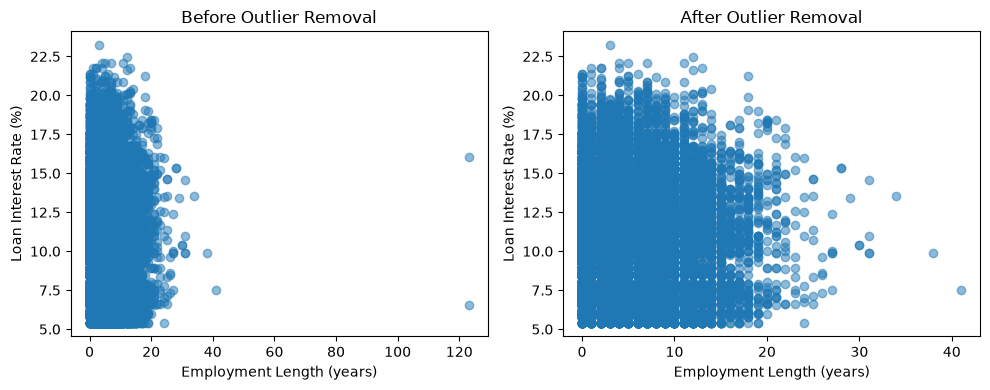

In [5]:
# Compare employment length and interest rate before and after applying the rule.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(df_before.person_emp_length, df_before.loan_int_rate, alpha=0.5)
axes[0].set_title("Before Outlier Removal")
axes[0].set_xlabel("Employment Length (years)")
axes[0].set_ylabel("Loan Interest Rate (%)")

axes[1].scatter(df_after.person_emp_length, df_after.loan_int_rate, alpha=0.5)
axes[1].set_title("After Outlier Removal")
axes[1].set_xlabel("Employment Length (years)")
axes[1].set_ylabel("Loan Interest Rate (%)")

plt.tight_layout()
plt.show()

## 3. Dealing with missing data

The notebook fills missing `loan_int_rate` values with the column mean and drops rows with missing `person_emp_length`.

Mean imputation is simple but can reduce variability and be influenced by skew. Dropping rows can also change the sample composition if missingness is systematic.

**Validation limitation:** imputation currently happens before the train/test split, so the mean includes information from future test rows. A stronger workflow splits first and fits imputation on training data only, preferably inside a scikit-learn `Pipeline` or `ColumnTransformer`.

In [6]:
# Work from the cleaned copy.
cr_loan = df_after.copy()

# Fill missing interest rates with the observed mean.
# For leakage-safe modeling, estimate this mean from training data only.
cr_loan["loan_int_rate"] = cr_loan["loan_int_rate"].fillna(
    value=cr_loan["loan_int_rate"].mean()
)

# Drop rows where employment length is missing.
cr_loan.drop(
    cr_loan[cr_loan.person_emp_length.isna()].index,
    inplace=True,
)

In [7]:
# Confirm that no missing employment-length values remain.
cr_loan[cr_loan.person_emp_length.isna()].index

Index([], dtype='int64')

## 4. Encode categorical variables

Logistic regression requires numeric inputs. `pd.get_dummies()` converts the selected categorical features into indicator columns. `drop_first=True` omits one reference category per variable to avoid redundant dummy columns.

For a more robust pipeline, fit encoders on training data and handle categories that may appear only in later data.

In [8]:
# Identify columns to treat as categorical predictors.
categorical_vars = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

# Convert categorical values into binary indicator columns.
# drop_first=True omits one reference category per variable.
cr_loan_encoded = pd.get_dummies(
    cr_loan,
    columns=categorical_vars,
    drop_first=True,
)

In [9]:
cr_loan_encoded

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,...,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
1,21,9600,5.0,1000,11.14,0,0.10,2,False,True,...,False,False,False,True,False,False,False,False,False,False
2,25,9600,1.0,5500,12.87,1,0.57,3,False,False,...,True,False,False,False,True,False,False,False,False,False
3,23,65500,4.0,35000,15.23,1,0.53,2,False,False,...,True,False,False,False,True,False,False,False,False,False
4,24,54400,8.0,35000,14.27,1,0.55,4,False,False,...,True,False,False,False,True,False,False,False,False,True
5,21,9900,2.0,2500,7.14,1,0.25,2,False,True,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,1.0,5800,13.16,0,0.11,30,False,False,...,False,True,False,False,True,False,False,False,False,False
32577,54,120000,4.0,17625,7.49,0,0.15,19,False,False,...,False,True,False,False,False,False,False,False,False,False
32578,65,76000,3.0,35000,10.99,1,0.46,28,False,False,...,False,False,False,True,False,False,False,False,False,False
32579,56,150000,5.0,15000,11.48,0,0.10,26,False,False,...,False,True,False,True,False,False,False,False,False,False


## 5. Define predictors and target

- **Target (`y`):** `loan_status`; class `1` represents default and class `0` represents non-default.
- **Features (`X`):** all remaining columns.

For a real lending workflow, verify that each predictor would be available at the time a decision is made and does not contain target leakage.

In [10]:
# Separate the outcome from the explanatory features.
X = cr_loan_encoded.drop("loan_status", axis=1)
y = cr_loan_encoded["loan_status"]

## 6. Train/test split

The split reserves 30% of observations for testing. `stratify=y` preserves approximately the same class proportions in each subset, and `random_state=42` makes the split reproducible.

**Limitation:** preprocessing and dummy encoding happen before this split. In a leakage-safe workflow, split the raw data first and fit all preprocessing steps on the training subset. Use a validation set to choose a threshold and keep the test set for final evaluation.

In [11]:
# Hold out 30% of observations for evaluation.
# Stratification approximately preserves target-class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

## 7. Fit a logistic-regression baseline

Logistic regression estimates the probability of default from the input features. Scikit-learn's default class prediction uses a probability threshold of 0.5.

The saved output from the original run contained a convergence warning. This means the optimizer did not report successful convergence. Feature scaling is a likely improvement because predictors can have very different numeric ranges. Resolve the warning and rerun the notebook before treating its results as final.

In [12]:
# Fit the baseline logistic-regression model.
# If convergence warnings occur, scale numeric features and fit preprocessing
# inside a Pipeline before treating the results as final.
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# Default class predictions use a probability cutoff of 0.5.
y_pred = logreg.predict(X_test)

c:\Users\hp\Documents\Risk Portfolio\quantitative-risk-model-validation\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Predicted default probabilities

`predict_proba()` returns probabilities for both classes. `[:, 1]` selects the probability of class `1` (default). These scores are used for ROC analysis and to test alternative classification thresholds.

In [13]:
# Probability assigned to class 1 (loan default) for each test observation.
y_pred_proba = logreg.predict_proba(X_test)[:, 1]
y_pred_proba

array([0.22414605, 0.05974643, 0.05596006, ..., 0.17843652, 0.05237811,
       0.24846203], shape=(9506,))

## 8. Evaluate baseline predictions

- **Accuracy:** fraction of all predictions that are correct.
- **Precision:** among predicted defaults, the fraction that actually defaulted.
- **Recall:** among actual defaults, the fraction identified by the model.
- **F1 score:** harmonic mean of precision and recall.

Accuracy alone can be misleading when non-defaults are much more common than defaults. The metrics below give a more complete view of model behavior.

In [14]:
# Evaluate class predictions made at the default 0.5 threshold.
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Metrics (threshold = 0.50):")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Model Evaluation Metrics (threshold = 0.50):
Accuracy:  0.8503
Precision: 0.7498
Recall:    0.4580
F1 Score:  0.5687


### Confusion matrix

Rows are actual classes; columns are predicted classes.

- **True negative (TN):** correctly predicted non-default.
- **False positive (FP):** predicted default, but no default occurred.
- **False negative (FN):** missed an actual default.
- **True positive (TP):** correctly identified default.

In credit risk, false negatives can mean missed credit losses; false positives can mean rejecting or flagging creditworthy borrowers. Their relative costs should inform threshold selection.

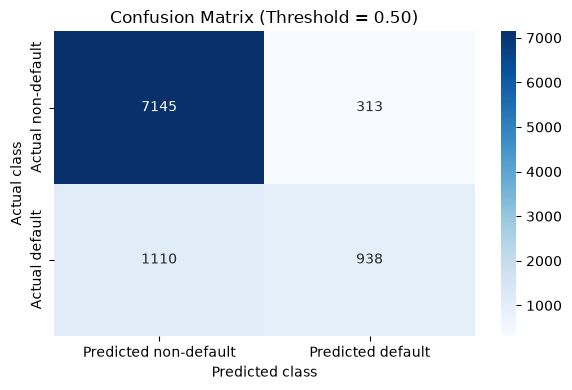

In [15]:
# Compute the confusion matrix for predictions at the default 0.5 threshold.
conf_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    xticklabels=["Predicted non-default", "Predicted default"],
    yticklabels=["Actual non-default", "Actual default"],
    cmap="Blues",
)
plt.title("Confusion Matrix (Threshold = 0.50)")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()

## 9. ROC curve and classification thresholds

The **ROC curve** plots:
- **True positive rate (TPR / recall):** `TP / (TP + FN)`.
- **False positive rate (FPR):** `FP / (FP + TN)`.

Each point corresponds to a different probability threshold. Lowering the threshold generally identifies more defaults but may also increase false positives. **ROC-AUC** summarizes ranking discrimination across thresholds; it does not by itself establish probability calibration or business value.

`roc_curve()` derives candidate thresholds from the predicted scores. Their number is determined by those scores and the function's handling of intermediate points, not chosen manually by the analyst.

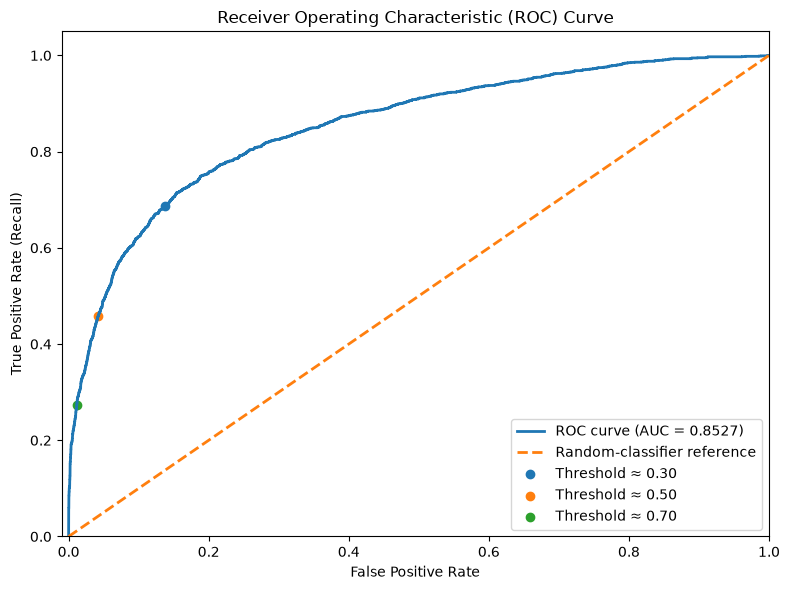

Model Evaluation Metrics (threshold = 0.70):
Accuracy:  0.8346
Precision: 0.8650
Recall:    0.2754
F1 Score:  0.4178


In [16]:
# Compute ROC coordinates from actual labels and predicted default probabilities.
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
# Diagonal reference line for a classifier with no ranking ability.
plt.plot([0, 1], [0, 1], lw=2, linestyle="--", label="Random-classifier reference")

# Mark the ROC points whose thresholds are closest to these illustrative cutoffs.
desired_thresholds = [0.3, 0.5, 0.7]

def find_closest_threshold(thresholds, desired_thresh):
    # Index of the ROC threshold closest to the requested cutoff.
    return np.argmin(np.abs(thresholds - desired_thresh))

for thresh in desired_thresholds:
    idx = find_closest_threshold(thresholds, thresh)
    plt.scatter(
        fpr[idx], tpr[idx],
        label=f"Threshold ≈ {thresholds[idx]:.2f}",
        marker="o",
    )

plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Compare metrics at an alternative 0.70 classification threshold.
threshold = 0.7
y_pred_threshold = (y_pred_proba >= threshold).astype(int)

accuracy = accuracy_score(y_test, y_pred_threshold)
precision = precision_score(y_test, y_pred_threshold, zero_division=0)
recall = recall_score(y_test, y_pred_threshold, zero_division=0)
f1 = f1_score(y_test, y_pred_threshold, zero_division=0)

print(f"Model Evaluation Metrics (threshold = {threshold:.2f}):")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

### Example: change the decision threshold to 0.70

Changing the threshold does not change predicted probabilities; it changes how probabilities become class labels. A higher cutoff makes the model more selective about labeling defaults. This often increases precision while reducing recall.

Do not select a threshold solely because it improves one metric. In practice, consider the cost of missed defaults, false alarms, lending policy, and probability calibration.

## 10. Find the threshold that maximizes F1

The next cell calculates F1 for each ROC threshold and reports the one with the highest score.

**Important evaluation caveat:** the target labels from the test set are used to select this threshold, so it is tuned to the test data. Its performance would be optimistic if presented as an unbiased final test result. A stronger workflow chooses a threshold using a validation set or cross-validation, then evaluates it once on a separate untouched test set.

In [17]:
# Calculate F1 for every candidate threshold.
f1_scores = []
for thresh in thresholds:
    y_pred_thresh = (y_pred_proba >= thresh).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_thresh, zero_division=0))

# Select the threshold with the highest F1 on this test set.
# This is exploratory: use validation data to tune a threshold in a stronger workflow.
optimal_idx = int(np.argmax(f1_scores))
optimal_threshold = thresholds[optimal_idx]
print(f"Threshold maximizing test-set F1 (exploratory): {optimal_threshold:.2f}")
print(f"F1 at selected threshold: {f1_scores[optimal_idx]:.4f}")

Threshold maximizing test-set F1 (exploratory): 0.32
F1 at selected threshold: 0.6326


## 11. Findings and next steps

### Findings from the notebook's saved run
- At the default **0.50 threshold**, the saved run reported accuracy **0.8646**, precision **0.7681**, recall **0.5322**, and F1 **0.6288**.
- At the illustrative **0.70 threshold**, the saved run reported accuracy **0.8398**, precision **0.8458**, recall **0.3135**, and F1 **0.4574**.
- The 0.70 threshold was more precise but detected a smaller share of actual defaults.
- The saved run selected **0.35** as the threshold maximizing F1 on the same test set. Treat this as exploratory, not as a final validated threshold.

These values come from the notebook's saved outputs. They may change after rerunning the notebook, particularly if the convergence issue or preprocessing workflow is improved.

### Improvements before presenting this as a validated model
1. **Resolve convergence:** scale numeric predictors and fit preprocessing and the estimator within a scikit-learn `Pipeline`.
2. **Prevent leakage:** split raw data before fitting imputers and encoders; fit preprocessing on training data only.
3. **Use validation for threshold selection:** keep the final test set untouched until the model and threshold are fixed.
4. **Assess class imbalance:** compare against a simple baseline and inspect precision-recall AUC as well as ROC-AUC.
5. **Check probability calibration:** if probabilities are used to estimate expected losses, assess calibration (for example, with a calibration curve and Brier score).
6. **Assess business impact and fairness:** evaluate the costs of missed defaults and false alarms, and review fairness, explainability, privacy, and regulatory considerations before any lending use.
7. **Improve reproducibility:** document the dataset source/version, package versions, and preprocessing and validation choices.

### Conclusion
This notebook establishes an interpretable logistic-regression baseline and demonstrates why threshold selection is a business decision as well as a statistical one. The results are useful for exploration; convergence, leakage-safe preprocessing, and independent threshold validation should be addressed before making strong performance claims.